In [42]:
import pandas as pd

file_path = 'cafe_sales (1).csv'
df = pd.read_csv(file_path)

print("Shape of Dataset:", df.shape)
df['date'] = pd.to_datetime(df['date'])
print("First Date:", df['date'].min().strftime('%Y-%m-%d'))
print("Last Date:", df['date'].max().strftime('%Y-%m-%d'))
print("Number of Branches:", df['branch'].nunique())

Shape of Dataset: (3170, 9)
First Date: 2026-01-01
Last Date: 2026-06-30
Number of Branches: 4


In [43]:

print("Columns:", df.columns.tolist())

df.columns = df.columns.str.strip().str.lower()

prod_col = [col for col in df.columns if 'product' in col or 'item' in col][0]
qty_col = [col for col in df.columns if 'quant' in col or 'qty' in col][0]


best_selling_product = df.groupby(prod_col)[qty_col].sum().idxmax()
best_selling_qty = df.groupby(prod_col)[qty_col].sum().max()
print(f"\nBest-selling product: {best_selling_product} ({best_selling_qty} units sold)")

Columns: ['order_id', 'date', 'branch', 'product', 'category', 'quantity', 'unit_price', 'total_sar', 'payment']

Best-selling product: Spanish Latte (927 units sold)


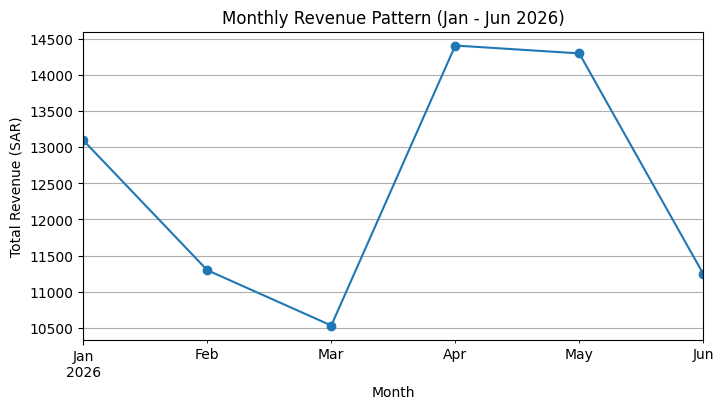

In [44]:
import matplotlib.pyplot as plt

df['year_month'] = df['date'].dt.to_period('M')
monthly_revenue = df.groupby('year_month')['total_sar'].sum()

plt.figure(figsize=(8, 4))
monthly_revenue.plot(kind='line', marker='o', color='#1f77b4')
plt.title('Monthly Revenue Pattern (Jan - Jun 2026)')
plt.xlabel('Month')
plt.ylabel('Total Revenue (SAR)')
plt.grid(True)
plt.show()

In [46]:
%%writefile app.py
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt

st.title("Qahwa Corner Sales Dashboard")

@st.cache_data
def load_data():
    df = pd.read_csv('cafe_sales (1).csv')
    df['date'] = pd.to_datetime(df['date'])
    return df

df = load_data()

selected_branch = st.sidebar.selectbox("Select Branch", ["All"] + list(df['branch'].unique()))

if selected_branch != "All":
    filtered_df = df[df['branch'] == selected_branch]
else:
    filtered_df = df

total_rev = filtered_df['total_sar'].sum()
st.metric(label=f"Total Revenue ({selected_branch})", value=f"{total_rev:,.2f} SAR")

st.subheader("Revenue by Product")
product_rev = filtered_df.groupby('product_name')['total_sar'].sum().reset_index()

fig, ax = plt.subplots()
ax.bar(product_rev['product_name'], product_rev['total_sar'], color='#2ca02c')
plt.xticks(rotation=45)
ax.set_ylabel("Total SAR")
st.pyplot(fig)

Writing app.py


In [32]:
print(df.columns)

Index(['order_id', 'date', 'branch', 'product', 'category', 'quantity',
       'unit_price', 'total_sar', 'payment'],
      dtype='object')
